In [ ]:
#EVALUATION-CLASSIFIER METRICES
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 1. Load dataset
df = pd.read_csv('drug_data.csv')

# 2. Preprocess missing values (fixed syntax to avoid pandas FutureWarnings)
df['Molecular_Weight'] = df['Molecular_Weight'].fillna(df['Molecular_Weight'].median())
df['LogP'] = df['LogP'].fillna(df['LogP'].median())
df['TPSA'] = df['TPSA'].fillna(df['TPSA'].median())

# 3. Encode categorical features
le = LabelEncoder()
df['Target_Protein_Enc'] = le.fit_transform(df['Target_Protein'])

# 4. Define Features (X) and Target Label (y)
X = df[['Molecular_Weight', 'LogP', 'Hydrogen_Bond_Donors',
        'Hydrogen_Bond_Acceptors', 'TPSA', 'Rotatable_Bonds', 'Target_Protein_Enc']]
y = df['Disease_Indication']

# 5. Split Dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 6. Initialize & Train Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 7. Make Predictions
y_pred = model.predict(X_test)

# 8. Print Clean Evaluation Output
print("=== Overall Classification Metrics ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

print("\n=== Detailed Per-Class Report ===")
print(classification_report(y_test, y_pred, zero_division=0))

=== Overall Classification Metrics ===
Accuracy:  0.1905
Precision: 0.1886
Recall:    0.1905
F1-Score:  0.1777

=== Detailed Per-Class Report ===
                     precision    recall  f1-score   support

            Anxiety       0.50      0.25      0.33         4
             Asthma       0.00      0.00      0.00         6
Bacterial Infection       0.16      0.27      0.20        11
             Cancer       0.25      0.14      0.18         7
         Depression       0.12      0.23      0.15        13
    Diabetes Type 2       0.25      0.25      0.25        12
           Epilepsy       0.00      0.00      0.00         5
   Fungal Infection       0.50      0.17      0.25         6
      Heart Failure       0.00      0.00      0.00         5
       Hypertension       0.31      0.38      0.34        13
       Inflammation       0.00      0.00      0.00         5
               Pain       0.00      0.00      0.00         6
      Schizophrenia       0.25      0.29      0.27         7

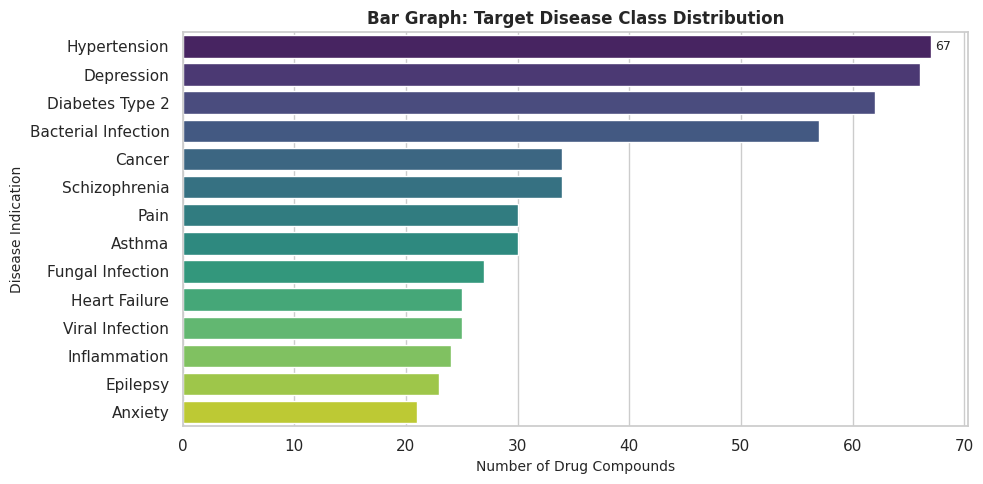

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load dataset
df = pd.read_csv('drug_data.csv')

# Plot Bar Graph
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

disease_counts = df['Disease_Indication'].value_counts()

# Set hue equal to y to eliminate the palette warning
ax = sns.barplot(
    x=disease_counts.values,
    y=disease_counts.index,
    hue=disease_counts.index,
    palette="viridis",
    legend=False,
)

# Optional: Add data count labels onto the bars
ax.bar_label(ax.containers[0], padding=3, fontsize=9)

plt.title(
    "Bar Graph: Target Disease Class Distribution",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Number of Drug Compounds", fontsize=10)
plt.ylabel("Disease Indication", fontsize=10)

plt.tight_layout()
plt.savefig("bar_graph.png", dpi=300)
plt.show()

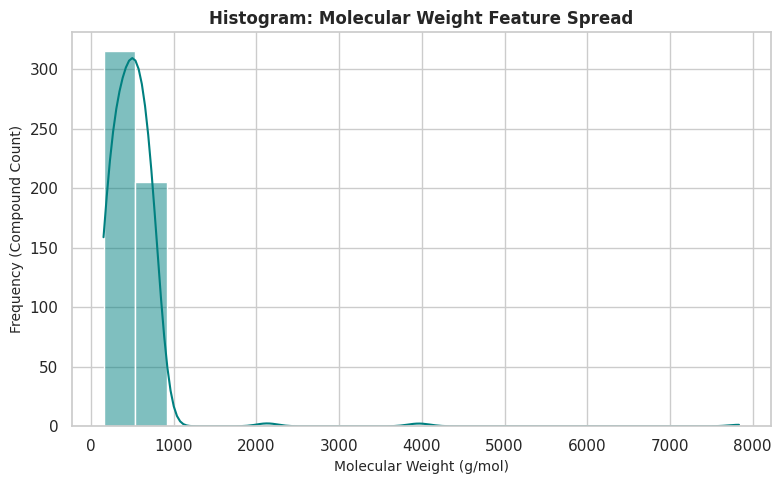

In [ ]:
#Histogram (Feature Distribution Evaluation)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean dataset
df = pd.read_csv('drug_data.csv')
df['Molecular_Weight'] = df['Molecular_Weight'].fillna(df['Molecular_Weight'].median())

# Plot Histogram
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

sns.histplot(df['Molecular_Weight'], kde=True, color="teal", bins=20)

plt.title("Histogram: Molecular Weight Feature Spread", fontsize=12, fontweight='bold')
plt.xlabel("Molecular Weight (g/mol)", fontsize=10)
plt.ylabel("Frequency (Compound Count)", fontsize=10)

plt.tight_layout()
plt.savefig("histogram.png", dpi=300)
plt.show()

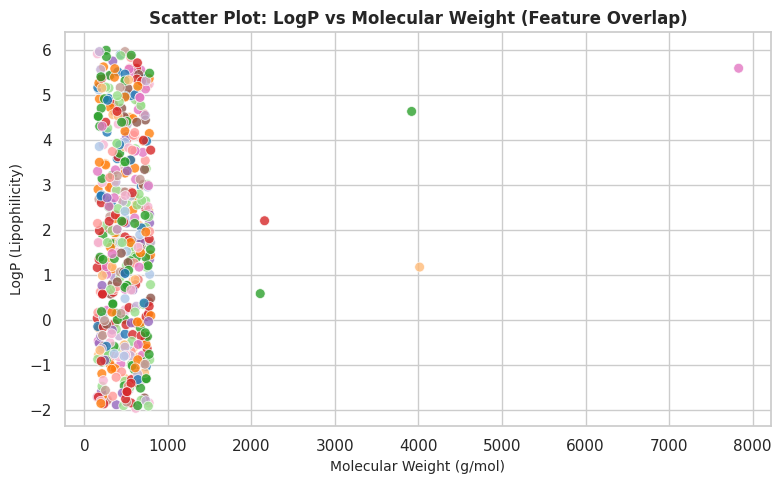

In [ ]:
#Scatter Plot (Feature Overlap & Separability)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and clean dataset
df = pd.read_csv('drug_data.csv')
df['Molecular_Weight'] = df['Molecular_Weight'].fillna(df['Molecular_Weight'].median())
df['LogP'] = df['LogP'].fillna(df['LogP'].median())

# Plot Scatter Plot
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=df,
    x='Molecular_Weight',
    y='LogP',
    hue='Disease_Indication',
    legend=False,
    palette="tab20",
    alpha=0.8,
    s=50
)

plt.title("Scatter Plot: LogP vs Molecular Weight (Feature Overlap)", fontsize=12, fontweight='bold')
plt.xlabel("Molecular Weight (g/mol)", fontsize=10)
plt.ylabel("LogP (Lipophilicity)", fontsize=10)

plt.tight_layout()
plt.savefig("scatter_plot.png", dpi=300)
plt.show()

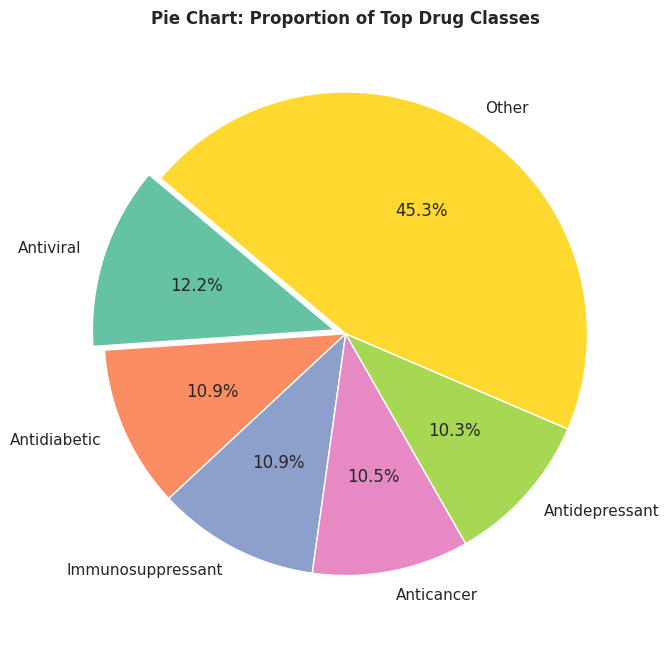

In [ ]:
#Pie Chart (Proportional Dataset Representation)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('drug_data.csv')

# Plot Pie Chart
plt.figure(figsize=(7, 7))

top_classes = df['Drug_Class'].value_counts().head(5)
other_count = df['Drug_Class'].value_counts().iloc[5:].sum()
pie_data = pd.concat([top_classes, pd.Series({'Other': other_count})])

plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("Set2"),
    startangle=140,
    explode=[0.05 if i == 0 else 0 for i in range(len(pie_data))]
)

plt.title("Pie Chart: Proportion of Top Drug Classes", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("pie_chart.png", dpi=300)
plt.show()

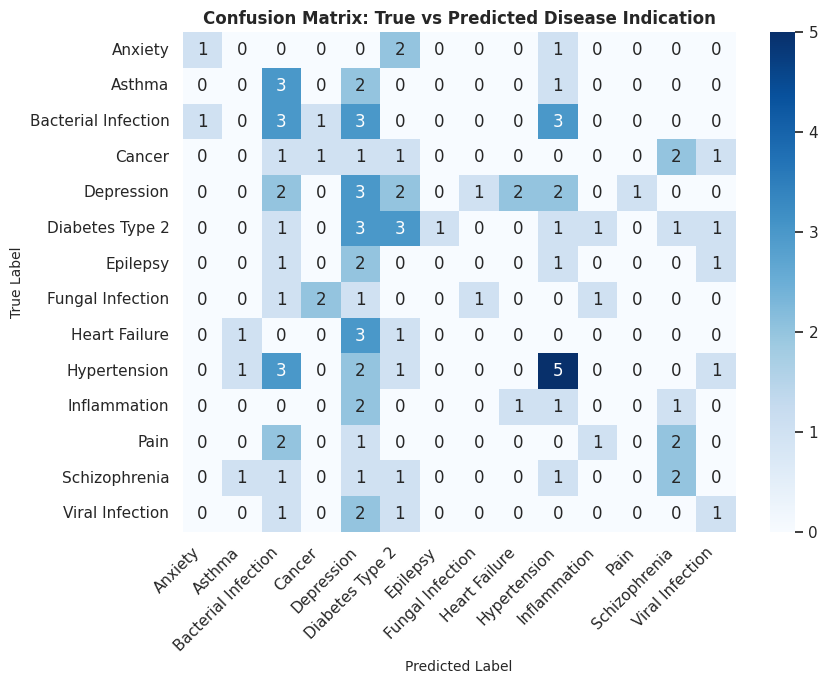

In [ ]:
#Confusion Matrix (Classification Error Heatmap)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix

# Load and preprocess dataset
df = pd.read_csv('drug_data.csv')
df['Molecular_Weight'] = df['Molecular_Weight'].fillna(df['Molecular_Weight'].median())
df['LogP'] = df['LogP'].fillna(df['LogP'].median())
df['TPSA'] = df['TPSA'].fillna(df['TPSA'].median())

le = LabelEncoder()
df['Target_Protein_Enc'] = le.fit_transform(df['Target_Protein'])

X = df[['Molecular_Weight', 'LogP', 'Hydrogen_Bond_Donors',
        'Hydrogen_Bond_Acceptors', 'TPSA', 'Rotatable_Bonds', 'Target_Protein_Enc']]
y = df['Disease_Indication']

# Train/Test Split & Fit Model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(9, 7))
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=clf.classes_,
    yticklabels=clf.classes_
)

plt.title('Confusion Matrix: True vs Predicted Disease Indication', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=10)
plt.ylabel('True Label', fontsize=10)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()